<a href="https://colab.research.google.com/github/ambaralmaraz73/Solving-Job-Shop-Scheduling-via-Search-Heuristics-and-Local-Search-/blob/main/JSSP_Instances_and_Benchmarks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

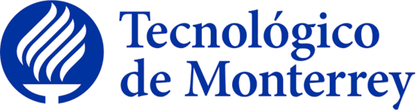

#**JOB-SHOP SCHEDULING PROBLEM FOR INSTANCES AND BENCHMARKS**

##1-Instances and benchmarks

In [4]:
import os
import random

# 1. Seeded instance generator
def generate_and_save_instances():
    random.seed(42)  # Seed to guarantee exact reproducibility
    os.makedirs('instances', exist_ok=True)

    # Configuration: (count, n_jobs, n_machines, difficulty_name)
    configs = [
        (10, 5, 5, "Easy"),    # 10 easy instances
        (8, 10, 10, "Medium"), # 8 medium instances
        (2, 15, 15, "Hard")    # 2 hard instances
    ]

    for count, n_jobs, n_machines, diff in configs:
        for i in range(1, count + 1):
            filename = f"instances/{diff}_{i}.txt"
            with open(filename, 'w') as f:
                f.write(f"{n_jobs} {n_machines}\n")
                for j in range(n_jobs):
                    ops = []
                    machines = list(range(1, n_machines + 1))
                    random.shuffle(machines)
                    for m in machines:
                        duration = random.randint(1, 10)
                        ops.append(f"M{m} {duration}")
                    f.write(" ".join(ops) + "\n")
    print("20 instances generated in the 'instances/' folder")

# 2. Custom instance loader
def load_custom_instance(filepath):
    """
    Reads a custom .txt file and converts it into the job dictionary
    that the algorithms need to function.
    """
    jobs_data = {}
    with open(filepath, 'r') as f:
        lines = f.readlines()
        n_jobs, n_machines = map(int, lines[0].strip().split())
        for idx in range(n_jobs):
            parts = lines[idx+1].strip().split()
            # Extracts pairs of (Machine, Duration)
            ops = [(parts[i], int(parts[i+1])) for i in range(0, len(parts), 2)]
            jobs_data[f"J{idx+1}"] = ops
    return jobs_data

# 3. Standard benchmark parser (OR-Library)
def load_or_library_instance(filepath):
    """
    Reads a standard OR-Library benchmark instance (e.g., ft10, la01).
    Standard format alternates: machine_id processing_time
    Note: OR-Library machines are usually 0-indexed. This function adjusts
    them to 1-indexed with an 'M' prefix to match the custom instances.
    """
    jobs_data = {}
    with open(filepath, 'r') as f:
        # read().split() automatically handles multiple spaces and newlines
        tokens = f.read().split()

    n_jobs = int(tokens[0])
    n_machines = int(tokens[1])

    pointer = 2
    for job_idx in range(n_jobs):
        ops = []
        for _ in range(n_machines):
            machine_id = int(tokens[pointer])
            duration = int(tokens[pointer + 1])

            # Convert 0-indexed integer to "M1", "M2" format
            formatted_machine = f"M{machine_id + 1}"
            ops.append((formatted_machine, duration))

            pointer += 2

        jobs_data[f"J{job_idx + 1}"] = ops

    return jobs_data

# Execute the generator immediately so the files exist
generate_and_save_instances()

20 instances generated in the 'instances/' folder


##2-Problem modeling (State, Action, Cost)

In [2]:
import copy

class JSPState:
    def __init__(self, jobs_data, job_progress=None, machine_free_time=None, job_end_time=None, schedule=None):
        self.jobs_data = jobs_data

        # 1. State
        # Dictionary: { "J1": 0, "J2": 0... } - Which operation is each job currently on?
        self.job_progress = job_progress if job_progress is not None else {j: 0 for j in jobs_data}

        # Dictionary: { "M1": 0, "M2": 0... } - At what minute does each machine become free?
        # We initialize it by extracting all unique machines from jobs_data
        if machine_free_time is None:
            machines = set(m for ops in jobs_data.values() for m, d in ops)
            self.machine_free_time = {m: 0 for m in machines}
        else:
            self.machine_free_time = machine_free_time

        # Dictionary: { "J1": 0, "J2": 0... } - At what minute did the job's previous operation finish?
        self.job_end_time = job_end_time if job_end_time is not None else {j: 0 for j in jobs_data}

        # Scheduled operations history
        self.schedule = schedule if schedule is not None else []

    @property
    def makespan(self):
        # 2. Cost
        # The makespan is the maximum time at which the last machine becomes free
        return max(self.machine_free_time.values()) if self.machine_free_time else 0

    def is_goal(self):
        # 3. Goal test
        # It is a goal if all jobs have completed all their operations
        return all(self.job_progress[j] == len(ops) for j, ops in self.jobs_data.items())

    def get_legal_actions(self):
        # 4. Legal actions
        # A valid action is choosing any job that hasn't finished yet
        return [j for j, ops in self.jobs_data.items() if self.job_progress[j] < len(ops)]

    def take_action(self, job_id):
        # 5. Transition (Apply action)
        # Extract the operation that this job needs to process next
        op_idx = self.job_progress[job_id]
        machine, duration = self.jobs_data[job_id][op_idx]

        # Start time calculation
        # The operation starts when the machine is free and the job has finished its previous operation
        start_time = max(self.machine_free_time[machine], self.job_end_time[job_id])
        end_time = start_time + duration

        # Create new dictionaries for the new state (immutability)
        new_progress = self.job_progress.copy()
        new_progress[job_id] += 1

        new_machine_time = self.machine_free_time.copy()
        new_machine_time[machine] = end_time

        new_job_end = self.job_end_time.copy()
        new_job_end[job_id] = end_time

        # Save the record: (Machine, Job (Op), Start, Duration)
        new_schedule = self.schedule.copy()
        new_schedule.append((machine, f"{job_id} (Op {op_idx + 1})", start_time, duration))

        # Return a new state
        return JSPState(self.jobs_data, new_progress, new_machine_time, new_job_end, new_schedule)

##3-Solving the problem

###3.1-"Depth-First Search"

In [5]:
import time  # To control the 60 seconds limit

def dfs_jssp(jobs_data, time_limit=60.0):
    # Function to execute DFS to solve the JSSP with a time limit
    # Registers the exact start time of execution
    start_time_global = time.time()
    # Starts a bool as False to detect if execution exceeds time limit
    timeout_reached = False
    t_best = None

    # Dynamic extraction of all unique machines present in the instance
    all_machines = set(machine for ops in jobs_data.values() for machine, duration in ops)

    # Initial state dynamically created based on jobs_data
    initial_state = {
        'progress': {job_id: 0 for job_id in jobs_data},        # Track index of pending operation per job
        'machine_free': {machine: 0 for machine in all_machines}, # Track time when each machine becomes free
        'job_free': {job_id: 0 for job_id in jobs_data},        # Track time when each job completes its last operation
        'schedule': []                                           # Cumulative schedule list with assigned operations
    }

    stack = [initial_state]             # Initiates the DFS search stack with initial state (LIFO)
    best_makespan = float('inf')        # Set best makespan to infinity so first valid solution replaces it
    best_schedule = None                # Variable to store the best schedule sequence found

    # Metrics
    expanded_nodes = 0
    max_frontier_size = len(stack)

    while stack:                        # Main search loop while nodes exist in stack
        # Track maximum size reached by the stack in memory
        max_frontier_size = max(max_frontier_size, len(stack))

        # Check if elapsed time exceeds the specified budget (60s)
        if (time.time() - start_time_global) > time_limit:
            timeout_reached = True      # Set timeout indicator to True
            break                       # Terminate search loop

        current = stack.pop()           # Extract last stack element (LIFO core operation in DFS)
        expanded_nodes += 1             # Increment node expansion counter

        # Goal test: verifies whether all jobs completed all assigned operations
        if all(current['progress'][job] == len(jobs_data[job]) for job in jobs_data):
            makespan = max(current['machine_free'].values()) if current['machine_free'] else 0
            if makespan < best_makespan:                               # Found a better solution:
                best_makespan = makespan                              # Update global best makespan
                best_schedule = current['schedule']                   # Save new optimal schedule
                t_best = time.time() - start_time_global              # Updates the exact time
            continue                                                  # Proceed to next node in stack

        # Generate available operations (successors / tree branching)
        for job_id, ops in jobs_data.items():                         # Iterate through each job and operations
            step = current['progress'][job_id]                        # Get index of current job operation
            if step < len(ops):                                       # If job has pending operations:
                machine, duration = ops[step]                         # Extract required machine and duration

                # Start time calculation:
                # Maximum between machine release time and job's previous operation completion time
                start_time = max(current['machine_free'][machine], current['job_free'][job_id])
                end_time = start_time + duration                      # Calculate operation completion time

                # Pruning / bounds check:
                # If completion time equals or exceeds current best makespan, prune branch
                if end_time >= best_makespan:
                    continue

                # Copy and update state dictionaries for successor node
                new_progress = current['progress'].copy()             # Copy progress dictionary
                new_progress[job_id] += 1                             # Increment processed operation index

                new_machine_free = current['machine_free'].copy()     # Copy machine release status
                new_machine_free[machine] = end_time                  # Update release time for used machine

                new_job_free = current['job_free'].copy()             # Copy job availability status
                new_job_free[job_id] = end_time                       # Update job completion time

                # Create new schedule by appending currently scheduled operation
                new_schedule = current['schedule'] + [{
                    'Machine': machine,
                    'Label': f"{job_id} (Op {step + 1})",
                    'Initial time': start_time,
                    'Duration': duration
                }]

                # Insert successor state into stack for future exploration
                stack.append({
                    'progress': new_progress,
                    'machine_free': new_machine_free,
                    'job_free': new_job_free,
                    'schedule': new_schedule
                })

    elapsed_time = time.time() - start_time_global                    # Calculate total execution elapsed time

    return best_makespan, best_schedule, elapsed_time, t_best, timeout_reached, expanded_nodes, max_frontier_size

# --- Execution on a single instance file ---
# To test any file, simply paste its path in the variable below.
# Examples:
# a) Custom instance:   'instances/Easy_1.txt' or 'instances/Dificil_1.txt'
# b) Standard benchmark: 'benchmarks/ft10.txt' or 'benchmarks/la36.txt'

instance_path = '/content/instances/Easy_1.txt'  # <--- PASTE THE DESIRED INSTANCE PATH HERE

# Extract the instance name from the file path
instance_name = os.path.basename(instance_path)

# Automatically select the correct loader based on the folder path
if 'benchmarks/' in instance_path:
    jobs_data_loaded = load_or_library_instance(instance_path)
else:
    jobs_data_loaded = load_custom_instance(instance_path)

# Execute DFS algorithm calling the function with loaded instance and 60s limit
optimal_makespan_dfs, optimal_schedule_dfs, time_dfs, t_best_dfs, timed_out_dfs, nodes_dfs, mem_dfs = dfs_jssp(jobs_data_loaded, time_limit=60.0)

# Success rate calculation (100% if a valid solution/makespan was found, 0% otherwise)
success_rate_dfs = 100.0 if (optimal_makespan_dfs != float('inf')) else 0.0

# Print results
print(f"Results for instance / benchmark: {instance_name}")
print(f"Best makespan found by DFS: {optimal_makespan_dfs}")
print(f"Execution time: {time_dfs:.4f} seconds")
print(f"Time to best solution: {t_best_dfs:.4f} seconds" if t_best_dfs is not None else "Time to best solution: N/A")
print(f"Success rate: {success_rate_dfs:.1f}%")
print(f"Expanded nodes (Iterations): {nodes_dfs}")
print(f"Max frontier size (Memory): {mem_dfs}")
if timed_out_dfs:
    print("Notice: The 60-second time limit has been reached")

print("\nOptimal sequence of operations:")
if optimal_schedule_dfs:                                      # If a valid schedule was found:
    for item in optimal_schedule_dfs:                         # Iterate through each recorded operation
        print(f"Machine: {item['Machine']} | {item['Label']} | Start: {item['Initial time']} | Duration: {item['Duration']}")
else:
    print("No schedule was found within the time limit.")

Results for instance / benchmark: Easy_1.txt
Best makespan found by DFS: 69
Execution time: 60.0000 seconds
Time to best solution: 28.5455 seconds
Success rate: 100.0%
Expanded nodes (Iterations): 23263739
Max frontier size (Memory): 51
Notice: The 60-second time limit has been reached

Optimal sequence of operations:
Machine: M5 | J5 (Op 1) | Start: 0 | Duration: 10
Machine: M3 | J5 (Op 2) | Start: 10 | Duration: 5
Machine: M2 | J5 (Op 3) | Start: 15 | Duration: 1
Machine: M1 | J5 (Op 4) | Start: 16 | Duration: 8
Machine: M4 | J5 (Op 5) | Start: 24 | Duration: 9
Machine: M1 | J4 (Op 1) | Start: 24 | Duration: 3
Machine: M3 | J4 (Op 2) | Start: 27 | Duration: 4
Machine: M5 | J4 (Op 3) | Start: 31 | Duration: 6
Machine: M5 | J3 (Op 1) | Start: 37 | Duration: 4
Machine: M2 | J2 (Op 1) | Start: 16 | Duration: 2
Machine: M3 | J2 (Op 2) | Start: 31 | Duration: 4
Machine: M5 | J2 (Op 3) | Start: 41 | Duration: 4
Machine: M4 | J1 (Op 1) | Start: 33 | Duration: 4
Machine: M4 | J4 (Op 4) | Star

###3.2-"A* and Weighted A* Search" with Ablation Study (H1 vs H2 and Weights 1.0, 1.5, 2.0)

In [ ]:
import os
import time
import heapq

def heuristic(progress, jobs_data, h_type="H1"):
    """
    Calculates the admissible heuristic h(n) for the A* search.
    H1 (Cheap): Max remaining processing time among all jobs. Fast but less informative.
    H2 (More informative): Max of H1 and the remaining workload among all machines.
    """
    # Admissibility: Both lower bounds underestimate or equal the true remaining makespan, ensuring A* optimality guarantees when weight = 1.0.
    # H1: Maximum Remaining Job Time (Individual Job Bottleneck / Lower Bound)
    max_job_remaining = 0
    for job_id, ops in jobs_data.items():
        step = progress[job_id]
        remaining_time = sum(duration for _, duration in ops[step:])
        if remaining_time > max_job_remaining:
            max_job_remaining = remaining_time

    if h_type == "H1":
        return max_job_remaining

    # H2: Maximum Machine Workload (Machine Bottleneck / Lower Bound)
    all_machines = set(machine for ops in jobs_data.values() for machine, duration in ops)
    machine_workload = {m: 0 for m in all_machines}

    for job_id, ops in jobs_data.items():
        step = progress[job_id]
        for machine, duration in ops[step:]:
            machine_workload[machine] += duration

    max_machine_remaining = max(machine_workload.values()) if machine_workload else 0

    # H2 dominates H1 by taking the tightest lower bound between job time and machine workload
    return max(max_job_remaining, max_machine_remaining)


def a_star_jssp(jobs_data, h_type="H1", weight=1.0, time_limit=60.0):
    # Function to execute A* / Weighted A* to solve the JSSP with a time limit
    # Registers the exact start time of execution
    start_time_global = time.time()
    # Starts a bool as False to detect if execution exceeds time limit
    timeout_reached = False
    time_to_best = None

    # Dynamic extraction of all unique machines present in the instance
    all_machines = set(machine for ops in jobs_data.values() for machine, duration in ops)

    # Initial state dynamically created based on jobs_data
    initial_state = {
        'progress': {job_id: 0 for job_id in jobs_data},          # Track index of pending operation per job
        'machine_free': {machine: 0 for machine in all_machines}, # Track time when each machine becomes free
        'job_free': {job_id: 0 for job_id in jobs_data},          # Track time when each job completes its last operation
        'schedule': []                                            # Cumulative schedule list with assigned operations
    }

    total_ops = sum(len(ops) for ops in jobs_data.values())       # Total number of operations across all jobs

    g_initial = 0
    h_initial = heuristic(initial_state['progress'], jobs_data, h_type)
    f_initial = g_initial + weight * h_initial

    counter = 0                                                    # Tie-breaker counter for Priority Queue
    open_set = [(f_initial, 0, counter, g_initial, initial_state)] # Priority Queue (Min-Heap) for A*

    best_makespan = float('inf')                                   # Set best makespan to infinity
    best_schedule = None                                           # Variable to store the best schedule sequence found

    # Metrics
    expanded_nodes = 0
    max_frontier_size = len(open_set)

    while open_set:                                             # Main search loop while nodes exist in heap
        # Track maximum size reached by the priority queue in memory
        max_frontier_size = max(max_frontier_size, len(open_set))

        # Check if elapsed time exceeds the specified budget (60s)
        if (time.time() - start_time_global) > time_limit:
            timeout_reached = True                              # Set timeout indicator to True
            break                                               # Terminate search loop

        # Extract node with lowest f-score from priority queue
        f_current, neg_ops, _, g_current, current = heapq.heappop(open_set)
        expanded_nodes += 1                                     # Increment node expansion counter

        # Pruning check: if current path cost already equals or exceeds best makespan found
        if g_current >= best_makespan:
            continue

        # Goal test: verifies whether all jobs completed all assigned operations
        completed_ops = sum(current['progress'].values())
        if completed_ops == total_ops:
            makespan = max(current['machine_free'].values()) if current['machine_free'] else 0
            if makespan < best_makespan:                        # Found a better solution:
                best_makespan = makespan                        # Update global best makespan
                best_schedule = current['schedule']             # Save new optimal schedule
                time_to_best = time.time() - start_time_global  # Track time when best solution was found
            continue                                            # Proceed to next node in heap

        # Generate available operations (successors / tree branching)
        for job_id, ops in jobs_data.items():                  # Iterate through each job and operations
            step = current['progress'][job_id]                 # Get index of current job operation
            if step < len(ops):                                # If job has pending operations:
                machine, duration = ops[step]                  # Extract required machine and duration

                # Start time calculation:
                # Maximum between machine release time and job's previous operation completion time
                start_time = max(current['machine_free'][machine], current['job_free'][job_id])
                end_time = start_time + duration               # Calculate operation completion time

                # Pruning / bounds check:
                # If completion time equals or exceeds current best makespan, prune branch
                if end_time >= best_makespan:
                    continue

                # Copy and update state dictionaries for successor node
                new_progress = current['progress'].copy()      # Copy progress dictionary
                new_progress[job_id] += 1                      # Increment processed operation index

                new_machine_free = current['machine_free'].copy() # Copy machine release status
                new_machine_free[machine] = end_time              # Update release time for used machine

                new_job_free = current['job_free'].copy()      # Copy job availability status
                new_job_free[job_id] = end_time                # Update job completion time

                # Compute g(n), h(n) and weighted f(n)
                new_g = max(new_machine_free.values()) if new_machine_free else 0
                new_h = heuristic(new_progress, jobs_data, h_type)
                new_f = new_g + weight * new_h

                # Create new schedule by appending currently scheduled operation
                new_schedule = current['schedule'] + [{
                    'Machine': machine,
                    'Label': f"{job_id} (Op {step + 1})",
                    'Initial time': start_time,
                    'Duration': duration
                }]

                new_completed_ops = completed_ops + 1
                counter += 1

                # Insert successor state into priority queue for future exploration
                heapq.heappush(open_set, (new_f, -new_completed_ops, counter, new_g, {
                    'progress': new_progress,
                    'machine_free': new_machine_free,
                    'job_free': new_job_free,
                    'schedule': new_schedule
                }))

    elapsed_time = time.time() - start_time_global              # Calculate total execution elapsed time

    return best_makespan, best_schedule, elapsed_time, time_to_best, timeout_reached, expanded_nodes, max_frontier_size


# --- Execution on a single instance file ---
# To test any file, simply paste its path in the variable below.
# Examples:
# a) Custom instance:    'instances/Easy_1.txt' or 'instances/Hard_1.txt'
# b) Standard benchmark: 'benchmarks/ft10.txt' or 'benchmarks/la36.txt'

instance_path = 'benchmarks/la36.txt'   # <--- PASTE THE DESIRED INSTANCE PATH HERE

# Extract the instance name from the file path
instance_name_astar = os.path.basename(instance_path)

# Automatically select the correct loader based on the folder path
if 'benchmarks/' in instance_path:
    jobs_data_loaded = load_or_library_instance(instance_path)
else:
    jobs_data_loaded = load_custom_instance(instance_path)


# --- Ablation Study: A* vs Weighted A* (H1 vs H2 and w=1.0, 1.5, 2.0) ---

weights_to_test = [1.0, 1.5, 2.0]     # w=1.0 (A* normal), w=1.5 and w=2.0 (Weighted A*)
heuristics_to_test = ["H1", "H2"]

print(f"Results for instance / benchmark: {instance_name_astar}")

for h in heuristics_to_test:
    for w in weights_to_test:
        alg_name = "A*" if w == 1.0 else f"Weighted A* (w={w})"
        print(f"\nRunning {alg_name} with heuristic {h}")
        print("-" * 50)

        makespan, sched, time_astar, t_best, timed_out_astar, nodes_astar, mem_astar = a_star_jssp(jobs_data_loaded, h_type=h, weight=w, time_limit=60.0)

        # It is a success (100%) if a valid solution was found (makespan other than infinity).
        success_rate = 100.0 if (makespan != float('inf')) else 0.0

        if makespan != float('inf'):
            print(f"Best makespan found by {alg_name}: {makespan}")
        else:
            print(f"Best makespan found by {alg_name}: N/A")

        print(f"Execution time: {time_astar:.4f} seconds")

        if t_best is not None:
            print(f"Time to best solution: {t_best:.4f} seconds")
        else:
            print("Time to best solution: N/A")

        print(f"Success rate: {success_rate:.1f}%")
        print(f"Expanded nodes (Iterations): {nodes_astar}")
        print(f"Max frontier size (Memory): {mem_astar}")

        if timed_out_astar:
            print("Notice: The 60-second time limit has been reached")

        if sched:
            print("\nOptimal sequence of operations:")
            for item in sched:
                print(f"Machine: {item['Machine']} | {item['Label']} | Start: {item['Initial time']} | Duration: {item['Duration']}")
        else:
            print("\nNotice: No schedule was found within the time limit.")

Results for instance / benchmark: la36.txt

Running A* with heuristic H1
--------------------------------------------------
Best makespan found by A*: N/A
Execution time: 60.0001 seconds
Time to best solution: N/A
Success rate: 0.0%
Expanded nodes (Iterations): 127786
Max frontier size (Memory): 1789005
Notice: The 60-second time limit has been reached

Notice: No schedule was found within the time limit.

Running Weighted A* (w=1.5) with heuristic H1
--------------------------------------------------
Best makespan found by Weighted A* (w=1.5): N/A
Execution time: 60.0003 seconds
Time to best solution: N/A
Success rate: 0.0%
Expanded nodes (Iterations): 132571
Max frontier size (Memory): 1855995
Notice: The 60-second time limit has been reached

Notice: No schedule was found within the time limit.

Running Weighted A* (w=2.0) with heuristic H1
--------------------------------------------------
Best makespan found by Weighted A* (w=2.0): N/A
Execution time: 61.4247 seconds
Time to best 

###3.3-Solving the problem with "Multi-Start Hill-Climbing"

In [ ]:
import time
import random
import os

def decode_schedule(sequence, jobs_data):
    """
    Decodes the operation-based sequence into an actual schedule,
    calculating the start times and the final makespan dynamically.

    Representation: Operation-based list representation where each job_id
    appears N times (N = number of operations in that job).
    """
    # Dynamic extraction of all unique machines present in the instance
    all_machines = set(machine for ops in jobs_data.values() for machine, duration in ops)

    # Initialize tracking variables for machine availability and job precedences
    machine_free = {machine: 0 for machine in all_machines}
    job_free = {job_id: 0 for job_id in jobs_data}
    progress = {job_id: 0 for job_id in jobs_data}
    schedule = []

    for job_id in sequence:
        step = progress[job_id]
        machine, duration = jobs_data[job_id][step]

        # Non-preemptive scheduling rule: Operation starts at max(machine_release_time, job_precedence_time)
        start_time = max(machine_free[machine], job_free[job_id])
        end_time = start_time + duration

        machine_free[machine] = end_time
        job_free[job_id] = end_time
        progress[job_id] += 1

        schedule.append({
            'Machine': machine,
            'Label': f"{job_id} (Op {step + 1})",
            'Initial time': start_time,
            'Duration': duration
        })

    # Makespan is defined as the total completion time across all machines
    makespan = max(machine_free.values()) if machine_free else 0
    return makespan, schedule


def generate_random_sequence(jobs_data):
    # Generates a valid random initial sequence representing a schedule.
    sequence = []
    for job, ops in jobs_data.items():
        sequence.extend([job] * len(ops))
    random.shuffle(sequence)
    return sequence


# --- Neighborhood Definitions ---

def get_neighbors_n1(sequence):

    # Neighborhood 1 (N1): Adjacent Swap.
    # Swaps only adjacent elements (i and i+1) in the sequence.

    neighbors = []
    for i in range(len(sequence) - 1):
        if sequence[i] != sequence[i + 1]:
            new_seq = sequence.copy()
            new_seq[i], new_seq[i + 1] = new_seq[i + 1], new_seq[i]
            neighbors.append(new_seq)
    return neighbors


def get_neighbors_n2(sequence):

    # Neighborhood 2 (N2): Global Swap (Strong Variant).
    # Swaps any two non-adjacent elements (i and j) across the sequence.

    neighbors = []
    for i in range(len(sequence)):
        for j in range(i + 2, len(sequence)):
            if sequence[i] != sequence[j]:
                new_seq = sequence.copy()
                new_seq[i], new_seq[j] = new_seq[j], new_seq[i]
                neighbors.append(new_seq)
    return neighbors


# --- Main Multi-Start Hill Climbing Algorithm ---

def multi_start_hill_climbing(jobs_data, time_limit=60.0):
    # Registers the exact start time of execution
    start_time_global = time.time()
    timeout_reached = False
    time_to_best = None

    best_makespan = float('inf')
    best_schedule = None

    expanded_nodes = 0
    restarts_count = 0

    while (time.time() - start_time_global) < time_limit:
        restarts_count += 1

        # 1. Random Start
        current_seq = generate_random_sequence(jobs_data)
        current_makespan, current_schedule = decode_schedule(current_seq, jobs_data)
        expanded_nodes += 1

        # Save initial random solution immediately if it improves the global best
        if current_makespan < best_makespan:
            best_makespan = current_makespan
            best_schedule = current_schedule
            time_to_best = time.time() - start_time_global

        # 2. Greedy Hill-Climbing Loop (Variable Neighborhood Descent)
        improved = True
        while improved:
            if (time.time() - start_time_global) > time_limit:
                timeout_reached = True
                break

            improved = False
            best_neighbor_seq = None
            best_neighbor_makespan = current_makespan
            best_neighbor_schedule = None

            # Evaluate Neighborhood 1
            neighbors = get_neighbors_n1(current_seq)

            for nb in neighbors:
                expanded_nodes += 1
                nb_makespan, nb_schedule = decode_schedule(nb, jobs_data)
                if nb_makespan < best_neighbor_makespan:
                    best_neighbor_makespan = nb_makespan
                    best_neighbor_seq = nb
                    best_neighbor_schedule = nb_schedule

            # If no improvement in N1, evaluate Neighborhood 2
            if best_neighbor_seq is None:
                neighbors_n2 = get_neighbors_n2(current_seq)
                for nb in neighbors_n2:
                    expanded_nodes += 1
                    nb_makespan, nb_schedule = decode_schedule(nb, jobs_data)
                    if nb_makespan < best_neighbor_makespan:
                        best_neighbor_makespan = nb_makespan
                        best_neighbor_seq = nb
                        best_neighbor_schedule = nb_schedule

            # Apply the best found move (if any)
            if best_neighbor_seq is not None:
                current_seq = best_neighbor_seq
                current_makespan = best_neighbor_makespan
                current_schedule = best_neighbor_schedule
                improved = True

                # Update global best immediately after a local improvement
                if current_makespan < best_makespan:
                    best_makespan = current_makespan
                    best_schedule = current_schedule
                    time_to_best = time.time() - start_time_global

        if timeout_reached:
            break

    # Check whether the main loop ended due to a timeout.
    if (time.time() - start_time_global) >= time_limit:
        timeout_reached = True

    elapsed_time = time.time() - start_time_global
    return best_makespan, best_schedule, elapsed_time, time_to_best, timeout_reached, expanded_nodes, restarts_count


# --- Execution on a single instance file ---

instance_path = 'benchmarks/la36.txt'  # <--- PASTE THE DESIRED INSTANCE PATH HERE
instance_name_hc = os.path.basename(instance_path)

# Automatically select the correct loader based on the folder path
if 'benchmarks/' in instance_path:
    jobs_data_loaded = load_or_library_instance(instance_path)
else:
    jobs_data_loaded = load_custom_instance(instance_path)

# Execute Hill Climbing algorithm calling the function with loaded instance
optimal_makespan, optimal_schedule, run_time, t_best, timed_out, nodes_hc, restarts = multi_start_hill_climbing(jobs_data_loaded, time_limit=60.0)

# Success rate calculation (100% if a solution was found, 0% if infinity/no solution)
success_rate = 100.0 if (optimal_makespan != float('inf')) else 0.0

# Print results using the exact output schema
print(f"Results for instance / benchmark: {instance_name_hc}")

if optimal_makespan != float('inf'):
    print(f"Best makespan found by Multi-Start Hill-Climbing: {optimal_makespan}")
else:
    print("Best makespan found by Multi-Start Hill-Climbing: N/A")

print(f"Execution time: {run_time:.4f} seconds")

if t_best is not None:
    print(f"Time to best solution: {t_best:.4f} seconds")
else:
    print("Time to best solution: N/A")

print(f"Success rate: {success_rate:.1f}%")
print(f"Expanded nodes (Iterations): {nodes_hc}")
print(f"Max frontier size (Restarts): {restarts}")

# Print the notification if a timeout occurred or if the time exceeded 60s.
if timed_out or run_time >= 60.0:
    print("Notice: The 60-second time limit has been reached")

if optimal_schedule:
    print("\nOptimal sequence of operations:")
    for item in optimal_schedule:
        print(f"Machine: {item['Machine']} | {item['Label']} | Start: {item['Initial time']} | Duration: {item['Duration']}")
else:
    print("\nNotice: No schedule was found within the time limit.")

Results for instance / benchmark: la36.txt
Best makespan found by Multi-Start Hill-Climbing: 1585
Execution time: 60.9351 seconds
Time to best solution: 60.9351 seconds
Success rate: 100.0%
Expanded nodes (Iterations): 261511
Max frontier size (Restarts): 1
Notice: The 60-second time limit has been reached

Optimal sequence of operations:
Machine: M12 | J2 (Op 1) | Start: 0 | Duration: 54
Machine: M10 | J3 (Op 1) | Start: 0 | Duration: 83
Machine: M2 | J12 (Op 1) | Start: 0 | Duration: 34
Machine: M3 | J12 (Op 2) | Start: 34 | Duration: 47
Machine: M5 | J8 (Op 1) | Start: 0 | Duration: 58
Machine: M5 | J1 (Op 1) | Start: 58 | Duration: 21
Machine: M8 | J11 (Op 1) | Start: 0 | Duration: 65
Machine: M4 | J13 (Op 1) | Start: 0 | Duration: 50
Machine: M6 | J4 (Op 1) | Start: 0 | Duration: 77
Machine: M12 | J10 (Op 1) | Start: 54 | Duration: 37
Machine: M6 | J3 (Op 2) | Start: 83 | Duration: 77
Machine: M6 | J9 (Op 1) | Start: 160 | Duration: 27
Machine: M3 | J3 (Op 3) | Start: 160 | Durati

##4-Import results

###4.1-Generation of .CSV file for "Depth-First Search"

In [ ]:
import os
import csv
import pandas as pd

# Output filename combining summary and detailed schedule
output_csv = f"results_DFS_{os.path.splitext(instance_name)[0]}.csv"

# 1. Write summary metrics section
summary_data = {
    'Algorithm': 'DFS',
    'Instance': instance_name,
    'Best Makespan': optimal_makespan_dfs if optimal_makespan_dfs != float('inf') else 'N/A',
    'Execution Time (s)': round(time_dfs, 4),
    'Time to Best (s)': round(t_best_dfs, 4) if t_best_dfs is not None else 'N/A',
    'Success Rate (%)': round(success_rate_dfs, 1),
    'Expanded Nodes': nodes_dfs,
    'Max Frontier Size': mem_dfs,
    'Timed Out': timed_out_dfs
}

with open(output_csv, mode='w', newline='', encoding='utf-8') as f:
    writer = csv.writer(f)

    # Section Header: Summary Metrics
    writer.writerow(['=== SUMMARY METRICS ==='])
    writer.writerow(list(summary_data.keys()))
    writer.writerow(list(summary_data.values()))

    # Blank line + Section Header: Detailed Schedule
    writer.writerow([])
    writer.writerow(['=== DETAILED SCHEDULE ==='])

# 2. Append detailed schedule section below
if optimal_schedule_dfs:
    schedule_df = pd.DataFrame(optimal_schedule_dfs)
    schedule_df.to_csv(output_csv, mode='a', index=False)

print(f"\nFile name: '{output_csv}'")


File name: 'results_DFS_la36.csv'


###4.2-Generation of .CSV file for "A* and Weighted A* Search"

In [ ]:
# Ablation Study: A* vs Weighted A* (H1 vs H2 and w=1.0, 1.5, 2.0)

weights_to_test = [1.0, 1.5, 2.0]     # w=1.0 (A* normal), w=1.5 and w=2.0 (Weighted A*)
heuristics_to_test = ["H1", "H2"]

# Output filename combining summary and detailed schedule
output_csv = f"results_AStar_{os.path.splitext(instance_name_astar)[0]}.csv"

# 1. Write section header and columns once before loops
with open(output_csv, mode='w', newline='', encoding='utf-8') as f:
    writer = csv.writer(f)
    writer.writerow(['=== SUMMARY METRICS ==='])
    headers = [
        'Algorithm', 'Heuristic', 'Weight', 'Instance', 'Best Makespan',
        'Execution Time (s)', 'Time to Best (s)', 'Success Rate (%)',
        'Expanded Nodes', 'Max Frontier Size', 'Timed Out'
    ]
    writer.writerow(headers)

# Variables to track best overall schedule
best_overall_makespan = float('inf')
best_overall_schedule = None

for h in heuristics_to_test:
    for w in weights_to_test:
        alg_name = "A*" if w == 1.0 else f"Weighted A* (w={w})"

        makespan, sched, time_astar, t_best, timed_out_astar, nodes_astar, mem_astar = a_star_jssp(
            jobs_data_loaded, h_type=h, weight=w, time_limit=60.0
        )

        success_rate = 100.0 if (makespan != float('inf')) else 0.0

        # Save best global schedule found across all iterations
        if makespan < best_overall_makespan:
            best_overall_makespan = makespan
            best_overall_schedule = sched

        # 2. Append summary metrics row for each iteration
        summary_data = {
            'Algorithm': alg_name,
            'Heuristic': h,
            'Weight': w,
            'Instance': instance_name_astar,
            'Best Makespan': makespan if makespan != float('inf') else 'N/A',
            'Execution Time (s)': round(time_astar, 4),
            'Time to Best (s)': round(t_best, 4) if t_best is not None else 'N/A',
            'Success Rate (%)': round(success_rate, 1),
            'Expanded Nodes': nodes_astar,
            'Max Frontier Size': mem_astar,
            'Timed Out': timed_out_astar
        }

        with open(output_csv, mode='a', newline='', encoding='utf-8') as f:
            writer = csv.writer(f)
            writer.writerow(list(summary_data.values()))


# 3. Append detailed schedule section at the very end
with open(output_csv, mode='a', newline='', encoding='utf-8') as f:
    writer = csv.writer(f)
    writer.writerow([])
    writer.writerow(['=== DETAILED SCHEDULE ==='])

# Append detailed schedule section below
if best_overall_schedule:
    schedule_df = pd.DataFrame(best_overall_schedule)
    schedule_df.to_csv(output_csv, mode='a', index=False)

print(f"\nFile name: '{output_csv}'")


File name: 'results_AStar_la36.csv'


###4.3-Generation of .CSV file for "Multi-Start Hill-Climbing"

In [ ]:
# Output filename combining summary and detailed schedule
output_csv = f"results_MSHC_{os.path.splitext(instance_name_hc)[0]}.csv"

# 1. Write summary metrics section
summary_data = {
    'Algorithm': 'Multi-Start Hill-Climbing',
    'Instance': instance_name_hc,
    'Best Makespan': optimal_makespan if optimal_makespan != float('inf') else 'N/A',
    'Execution Time (s)': round(run_time, 4),
    'Time to Best (s)': round(t_best, 4) if t_best is not None else 'N/A',
    'Success Rate (%)': round(success_rate, 1),
    'Expanded Nodes': nodes_hc,
    'Max Frontier Size (Restarts)': restarts,
    'Timed Out': timed_out
}

with open(output_csv, mode='w', newline='', encoding='utf-8') as f:
    writer = csv.writer(f)

    # Section Header: Summary Metrics
    writer.writerow(['=== SUMMARY METRICS ==='])
    writer.writerow(list(summary_data.keys()))
    writer.writerow(list(summary_data.values()))

    # Blank line + Section Header: Detailed Schedule
    writer.writerow([])
    writer.writerow(['=== DETAILED SCHEDULE ==='])

# 2. Append detailed schedule section below
if optimal_schedule:
    schedule_df = pd.DataFrame(optimal_schedule)
    schedule_df.to_csv(output_csv, mode='a', index=False)

print(f"\nFile name: '{output_csv}'")


File name: 'results_MSHC_la36.csv'
